<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/03_insurance_fraud_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# Vehicle Insurance Fraud Detection with an Interpretable Decision Tree

## Research question

Can a shallow CART Decision Tree identify potentially fraudulent vehicle-insurance claims while keeping the learned rules understandable?

**Purpose.** Fraud detection is a **binary classification** problem: each claim is labeled either legitimate (`N`, 0) or potentially fraudulent (`Y`, 1). The model is an educational triage baseline, not an automatic rejection system.

## 1. Basic definitions and formulas

| Term | Simple meaning |
| --- | --- |
| Classification | Predict a category, such as fraud or no fraud. |
| Feature | An input variable used to make a prediction, such as claim amount or incident severity. |
| Target | The answer the model learns to predict, here `fraud_reported`. |
| Decision tree | A sequence of if/then questions that splits claims into increasingly similar groups. |
| Node | A question or decision point in the tree. |
| Leaf | A final region where the tree makes a prediction. |
| Entropy | A measure of uncertainty or disorder in a node. Lower is purer. |
| Class imbalance | When one class occurs much more often than another. |

### Entropy and information gain

$$Entropy = -\sum_{k=1}^{K}p_k\log_2(p_k)$$

- $K$ = number of classes
- $p_k$ = proportion of class $k$ in the node

Entropy is 0 when every claim in a node has the same class. It is larger when the node contains a more even mixture of classes.

The tree chooses the split with the greatest information gain:

$$Information\ Gain = Entropy(parent) - Weighted\ Entropy(children)$$

In simple words, the tree asks which question reduces uncertainty the most.

### Confusion-matrix metrics

| Metric | Formula | Meaning |
| --- | --- | --- |
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | Overall proportion correct |
| Precision | $TP/(TP+FP)$ | Of flagged claims, how many are actually fraud |
| Recall / sensitivity | $TP/(TP+FN)$ | Of fraudulent claims, how many were found |
| Specificity | $TN/(TN+FP)$ | Of legitimate claims, how many were left unflagged |
| F1 score | $2(Precision)(Recall)/(Precision+Recall)$ | Balance of precision and recall |
| ROC-AUC | Area under the ROC curve | Ranking quality across probability thresholds |

- `TP`: fraud correctly flagged; `TN`: legitimate correctly cleared
- `FP`: legitimate claim incorrectly flagged; `FN`: fraud missed

In fraud work, recall is often important because missing fraud can be costly, but precision matters because every investigation consumes time.

## 2. Dataset, source, and problem statement

**Source.** [Vehicle Insurance Claim Fraud Detection Dataset](https://www.kaggle.com/datasets/gunavathibaskaran/fraud-insurance-analysis), published on Kaggle. The expected file is `insurance_claims.csv`. Download the exact version, record the access date, and place the file beside this notebook, in `data/`, or in `/content/`.

The dataset contains policy information, insured-person information, incident details, claim amounts, vehicle information, and the target `fraud_reported`.

**Problem statement.** Build an interpretable first-pass model that helps an insurer prioritize claims for human review. A positive prediction means “review this claim,” not “the claimant committed fraud.”

**INSIGHT - 1:** Because the target is a category, classification metrics and a confusion matrix are appropriate. Accuracy alone is not enough when fraudulent claims are the minority.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    make_scorer,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
            

In [2]:
DATA_FILENAME = "insurance_claims.csv"
candidates = [
    Path(DATA_FILENAME),
    Path("data") / DATA_FILENAME,
    Path("/content") / DATA_FILENAME,
    Path("/content/drive/MyDrive") / DATA_FILENAME,
]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Download insurance_claims.csv from the cited Kaggle source and place it "
        "beside this notebook, in data/, or in /content/."
    )

df_raw = pd.read_csv(dataset_path, na_values=["?", "Unknown", "unknown"])
target_col = next(
    (column for column in ["fraud_reported", "FraudFound_P", "FraudFound", "label"] if column in df_raw),
    None,
)
if target_col is None:
    raise KeyError("Could not find a fraud target column.")

df_raw[target_col] = (
    df_raw[target_col].astype(str).str.strip().str.upper().map({"Y": 1, "N": 0, "1": 1, "0": 0})
)
if df_raw[target_col].isna().any():
    raise ValueError("The target contains values other than Y/N or 1/0.")

print(f"Loaded {dataset_path}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Target column: {target_col}")
display(df_raw.head())
            

Loaded data/insurance_claims.csv: 1,000 rows x 39 columns
Target column: fraud_reported


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital-gains,capital-loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,17-10-2014,OH,250/500,1000,1406.91,0,466132,MALE,MD,craft-repair,sleeping,husband,53300,0,25-01-2015,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5,1,YES,1,2,YES,71610,6510,13020,52080,Saab,92x,2004,1
1,228,42,342868,27-06-2006,IN,250/500,2000,1197.22,5000000,468176,MALE,MD,machine-op-inspct,reading,other-relative,0,0,21-01-2015,Vehicle Theft,NaN,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8,1,NaN,0,0,NaN,5070,780,780,3510,Mercedes,E400,2007,1
2,134,29,687698,06-09-2000,OH,100/300,2000,1413.14,5000000,430632,FEMALE,PhD,sales,board-games,own-child,35100,0,22-02-2015,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7,3,NO,2,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,0
3,256,41,227811,25-05-1990,IL,250/500,2000,1415.74,6000000,608117,FEMALE,PhD,armed-forces,board-games,unmarried,48900,-62400,10-01-2015,Single Vehicle Collision,Front Collision,Major Damage,Police,OH,Arlington,6956 Maple Drive,5,1,NaN,1,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,1
4,228,44,367455,06-06-2014,IL,500/1000,1000,1583.91,6000000,610706,MALE,Associate,sales,board-games,unmarried,66000,-46000,17-02-2015,Vehicle Theft,NaN,Minor Damage,NaN,NY,Arlington,3041 3rd Ave,20,1,NO,0,1,NO,6500,1300,650,4550,Accura,RSX,2009,0


,dtype
months_as_customer,int64
age,int64
policy_number,int64
policy_bind_date,str
policy_state,str
policy_csl,str
policy_deductable,int64
policy_annual_premium,float64
umbrella_limit,int64
insured_zip,int64


,missing_values
property_damage,360
police_report_available,343
collision_type,178
authorities_contacted,91
months_as_customer,0
age,0
policy_number,0
policy_deductable,0
policy_csl,0
policy_state,0


,count,percentage
fraud_reported,,
No Fraud,753,75.3
Fraud,247,24.7


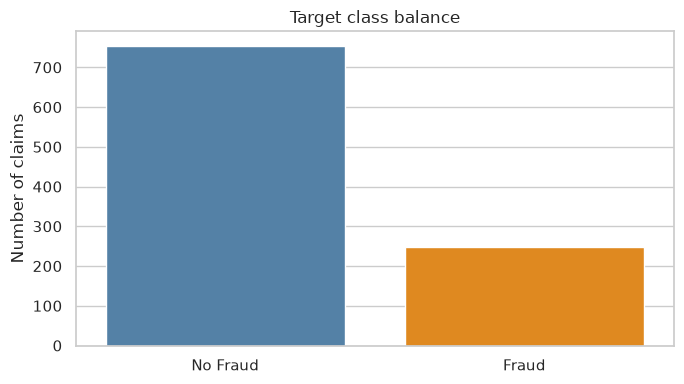

In [3]:
display(df_raw.dtypes.rename("dtype").to_frame())
display(df_raw.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
class_counts = df_raw[target_col].value_counts().sort_index()
class_summary = pd.DataFrame(
    {"count": class_counts, "percentage": (class_counts / len(df_raw) * 100).round(2)}
)
display(class_summary.rename(index={0: "No Fraud", 1: "Fraud"}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    x=class_summary.index.map({0: "No Fraud", 1: "Fraud"}),
    y=class_summary["count"],
    hue=class_summary.index.map({0: "No Fraud", 1: "Fraud"}),
    palette=["steelblue", "darkorange"],
    legend=False,
    ax=ax,
)
ax.set_title("Target class balance")
ax.set_xlabel("")
ax.set_ylabel("Number of claims")
plt.tight_layout()
plt.show()
            

## 3. Data cleaning and preprocessing

The cleaning plan is:

1. Standardize the fraud label to binary 0/1.
2. Remove exact duplicates and rows with an unusable target.
3. Exclude identifiers, dates, locations, and other high-cardinality fields that are not suitable for this compact baseline or could leak claim identity.
4. Separate the target before modeling.
5. Fit imputation and one-hot encoding **inside a pipeline on training folds only**. This prevents test-set information from entering preprocessing.

The decision tree does not require feature scaling. Numeric values are imputed with their training median; categorical values use their training most-frequent category.

In [4]:
df = df_raw.copy()
before_rows = len(df)
df = df.drop_duplicates().copy()
df = df.dropna(subset=[target_col]).copy()

columns_to_drop = [
    "policy_number", "policy_bind_date", "insured_zip", "incident_date",
    "incident_location", "auto_model", "policy_state", "insured_hobbies",
]
excluded_columns = [column for column in columns_to_drop if column in df.columns]
df_model = df.drop(columns=excluded_columns).copy()

print(f"Exact duplicate rows removed: {before_rows - len(df_raw.drop_duplicates()):,}")
print(f"Rows with missing target removed: {df_raw[target_col].isna().sum():,}")
print(f"Excluded metadata/high-cardinality columns: {excluded_columns}")
print(f"Modeling table: {df_model.shape[0]:,} rows x {df_model.shape[1]:,} columns")
display(df_model.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
            

Exact duplicate rows removed: 0
Rows with missing target removed: 0
Excluded metadata/high-cardinality columns: ['policy_number', 'policy_bind_date', 'insured_zip', 'incident_date', 'incident_location', 'auto_model', 'policy_state', 'insured_hobbies']
Modeling table: 1,000 rows x 31 columns


,missing_values
property_damage,360
police_report_available,343
collision_type,178
authorities_contacted,91
policy_deductable,0
age,0
months_as_customer,0
insured_sex,0
insured_education_level,0
insured_relationship,0


In [5]:
numeric_columns = df_model.drop(columns=[target_col]).select_dtypes(include=np.number).columns.tolist()
categorical_columns = df_model.drop(columns=[target_col]).select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric features before encoding: {len(numeric_columns)}")
print(f"Categorical features before encoding: {len(categorical_columns)}")
display(df_model[numeric_columns].describe().T)
            

Numeric features before encoding: 16
Categorical features before encoding: 14


,count,mean,std,min,25%,50%,75%,max
months_as_customer,1000.0,2.039540e+02,1.151132e+02,0.00,115.7500,199.5,276.250,479.00
age,1000.0,3.894800e+01,9.140287e+00,19.00,32.0000,38.0,44.000,64.00
policy_deductable,1000.0,1.136000e+03,6.118647e+02,500.00,500.0000,1000.0,2000.000,2000.00
policy_annual_premium,1000.0,1.256406e+03,2.441674e+02,433.33,1089.6075,1257.2,1415.695,2047.59
umbrella_limit,1000.0,1.101000e+06,2.297407e+06,-1000000.00,0.0000,0.0,0.000,10000000.00
capital-gains,1000.0,2.512610e+04,2.787219e+04,0.00,0.0000,0.0,51025.000,100500.00
capital-loss,1000.0,-2.679370e+04,2.810410e+04,-111100.00,-51500.0000,-23250.0,0.000,0.00
incident_hour_of_the_day,1000.0,1.164400e+01,6.951373e+00,0.00,6.0000,12.0,17.000,23.00
number_of_vehicles_involved,1000.0,1.839000e+00,1.018880e+00,1.00,1.0000,1.0,3.000,4.00
bodily_injuries,1000.0,9.920000e-01,8.201272e-01,0.00,0.0000,1.0,2.000,2.00


**INSIGHT - 2:** Removing identifiers and location strings reduces memorization risk. These fields may be useful for a specialized study, but they can make a baseline look better without generalizing to new claims.

**INSIGHT - 3:** Imputation and encoding are deferred to the pipeline. This is safer than filling and encoding the complete dataset before the split because cross-validation must not see validation-fold information.

## 4. Exploratory data analysis

We examine the target balance, missingness, numerical distributions, and how fraud rates vary across important categorical variables. A group difference is descriptive; it does not prove that the variable causes fraud.

,count,mean,fraud_percentage
incident_severity,,,
Major Damage,276,0.605072,60.507246
Total Loss,280,0.128571,12.857143
Minor Damage,354,0.107345,10.734463
Trivial Damage,90,0.066667,6.666667


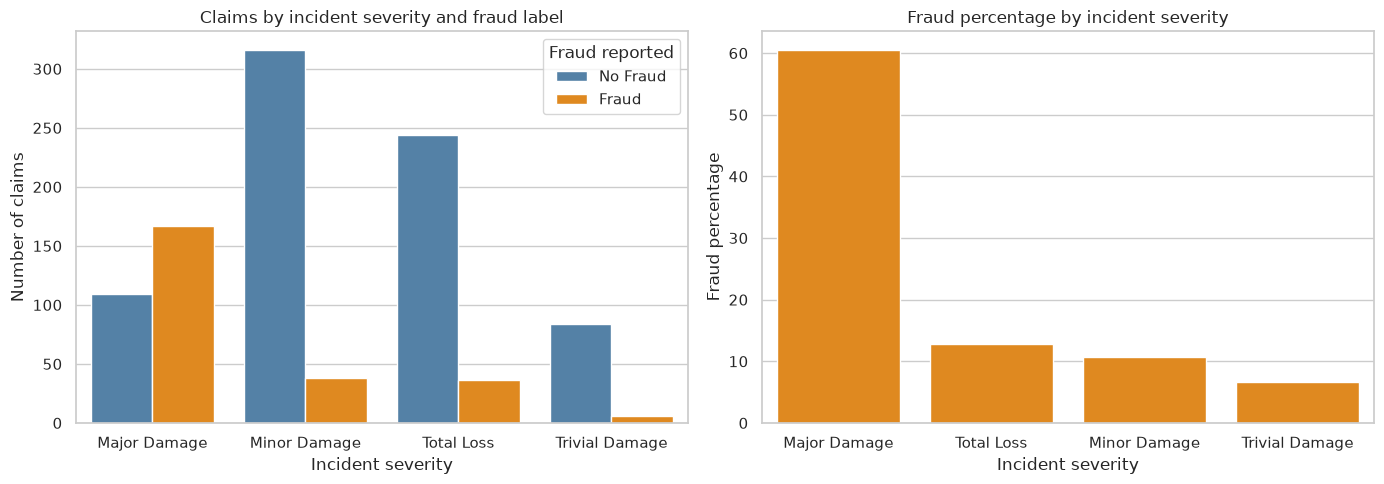

In [6]:
fraud_rate_by_severity = (
    df_model.groupby("incident_severity")[target_col]
    .agg(["count", "mean"])
    .assign(fraud_percentage=lambda table: table["mean"] * 100)
    .sort_values("fraud_percentage", ascending=False)
)
display(fraud_rate_by_severity)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(
    data=df_model,
    x="incident_severity",
    hue=target_col,
    palette=["steelblue", "darkorange"],
    ax=axes[0],
)
axes[0].set_title("Claims by incident severity and fraud label")
axes[0].set_xlabel("Incident severity")
axes[0].set_ylabel("Number of claims")
axes[0].legend(title="Fraud reported", labels=["No Fraud", "Fraud"])
sns.barplot(
    data=fraud_rate_by_severity.reset_index(),
    x="incident_severity",
    y="fraud_percentage",
    color="darkorange",
    ax=axes[1],
)
axes[1].set_title("Fraud percentage by incident severity")
axes[1].set_xlabel("Incident severity")
axes[1].set_ylabel("Fraud percentage")
plt.tight_layout()
plt.show()
            

fraud_reported                        0             1
total_claim_amount mean    50288.605578  60302.105263
                   median  56520.000000  61290.000000
injury_claim       mean     7179.229748   8208.340081
                   median   6620.000000   7240.000000
property_claim     mean     7018.884462   8560.121457
                   median   6560.000000   7440.000000
vehicle_claim      mean    36090.491368  43533.643725
                   median  41220.000000  44800.000000

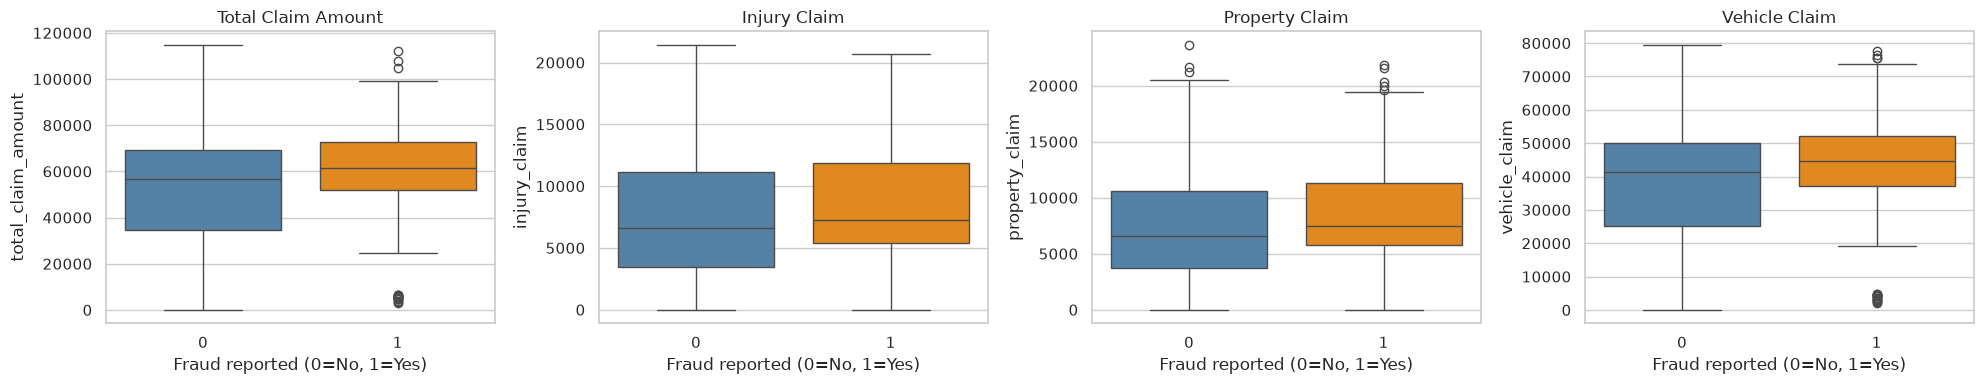

In [7]:
claim_amount_columns = [
    column for column in ["total_claim_amount", "injury_claim", "property_claim", "vehicle_claim"]
    if column in df_model.columns
]
if claim_amount_columns:
    display(df_model.groupby(target_col)[claim_amount_columns].agg(["mean", "median"]).T)
    fig, axes = plt.subplots(1, len(claim_amount_columns), figsize=(5 * len(claim_amount_columns), 4))
    axes = np.atleast_1d(axes)
    for ax, column in zip(axes, claim_amount_columns):
        sns.boxplot(data=df_model, x=target_col, y=column, hue=target_col, palette=["steelblue", "darkorange"], legend=False, ax=ax)
        ax.set_title(column.replace("_", " ").title())
        ax.set_xlabel("Fraud reported (0=No, 1=Yes)")
    plt.tight_layout()
    plt.show()
            

,fraud_reported
fraud_reported,1.000000
vehicle_claim,0.170049
total_claim_amount,0.163651
property_claim,0.137835
injury_claim,0.090975
umbrella_limit,0.058622
number_of_vehicles_involved,0.051839
witnesses,0.049497
bodily_injuries,0.033877
months_as_customer,0.020544


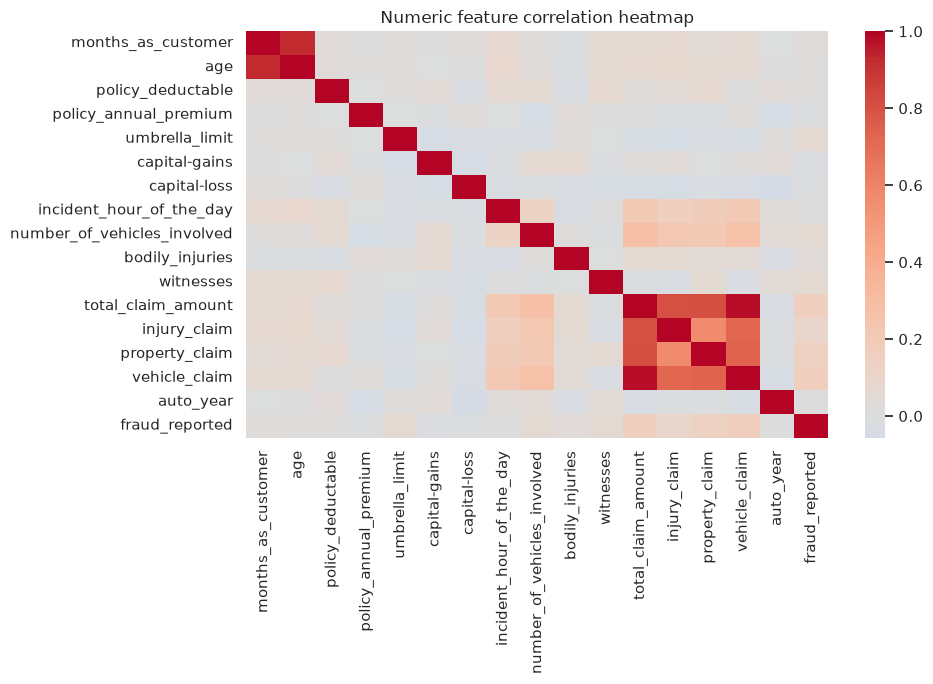

In [8]:
numeric_correlation = df_model.select_dtypes(include=np.number).corr()
display(numeric_correlation[[target_col]].sort_values(target_col, ascending=False))

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_correlation, cmap="coolwarm", center=0, annot=False)
plt.title("Numeric feature correlation heatmap")
plt.tight_layout()
plt.show()
            

**INSIGHT - 4:** The fraud percentage, rather than only the claim count, is the useful comparison when groups have different sizes.

**INSIGHT - 5:** Claim amounts and incident characteristics may show different distributions by class, but overlapping boxplots mean that no single variable is a complete fraud detector.

**INSIGHT - 6:** Correlation is a linear association measure for numeric columns. It does not capture all categorical or nonlinear decision-tree relationships.

## 5. Feature selection and processing

The model keeps claim, policy, incident, and vehicle characteristics that could plausibly be available when a claim is reviewed. It excludes direct identifiers, raw dates, high-cardinality location fields, and `auto_model` in this compact baseline.

The data is split **80% training / 20% testing** with stratification. Stratification preserves the fraud proportion in both partitions. The training data is used for fitting preprocessing and the tree; the untouched test partition is used once for final evaluation.

In [9]:
X = df_model.drop(columns=[target_col])
y = df_model[target_col].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Testing rows: {len(X_test):,} ({len(X_test) / len(X):.0%})")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
            

Training rows: 800 (80%)
Testing rows: 200 (20%)
Numeric features: 16
Categorical features: 14


In [10]:
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        (
            "categorical",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", encoder),
                ]
            ),
            categorical_features,
        ),
    ],
    remainder="drop",
)

tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
)
model = Pipeline([("preprocess", preprocessor), ("classifier", tree)])
print("Pipeline created: imputation -> one-hot encoding -> balanced shallow CART")
            

Pipeline created: imputation -> one-hot encoding -> balanced shallow CART


**INSIGHT - 7:** A shallow tree (`max_depth=4`) and minimum leaf size keep the rules inspectable and reduce overfitting. `class_weight="balanced"` gives the minority fraud class more influence during training.

## 6. Model implementation and evaluation

The model is evaluated with stratified five-fold cross-validation on the training partition, followed by one untouched test evaluation. For this classification problem, confusion-matrix metrics are primary:

- **Accuracy:** overall correctness.
- **Precision:** how trustworthy a fraud flag is.
- **Recall/sensitivity:** how much fraud is caught.
- **Specificity:** how much legitimate business is not unnecessarily flagged.
- **F1:** balance between precision and recall.
- **ROC-AUC:** ranking quality using predicted probabilities.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def specificity_score(y_true, y_pred):
    tn, fp, _, _ = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp) if tn + fp else 0.0


cv_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "specificity": make_scorer(specificity_score),
    "f1": "f1",
    "roc_auc": "roc_auc",
}
cv_result = cross_validate(model, X_train, y_train, cv=cv, scoring=cv_scoring, n_jobs=-1)
cv_summary = pd.DataFrame(
    {
        "mean": [cv_result[f"test_{metric}"].mean() for metric in cv_scoring],
        "std": [cv_result[f"test_{metric}"].std() for metric in cv_scoring],
    },
    index=cv_scoring,
)
display(cv_summary)
            

,mean,std
accuracy,0.775000,0.033072
precision,0.542282,0.055135
recall,0.676667,0.037590
specificity,0.807149,0.045631
f1,0.599916,0.035089
roc_auc,0.739987,0.032349


In [12]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
train_pred = model.predict(X_train)

print(f"Tree depth: {model.named_steps['classifier'].get_depth()}")
print(f"Leaf nodes: {model.named_steps['classifier'].get_n_leaves()}")
print(f"Train accuracy: {accuracy_score(y_train, train_pred):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Generalization gap: {abs(accuracy_score(y_train, train_pred) - accuracy_score(y_test, y_pred)):.2%}")
            

Tree depth: 4
Leaf nodes: 11
Train accuracy: 80.00%
Test accuracy: 78.50%
Generalization gap: 1.50%


In [13]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
test_metrics = pd.Series(
    {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall / Sensitivity": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else 0.0,
        "F1 score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
    },
    name="test_value",
)
display(test_metrics.to_frame())
print(classification_report(y_test, y_pred, target_names=["No Fraud", "Fraud"], zero_division=0))
            

,test_value
Accuracy,0.785000
Precision,0.551724
Recall / Sensitivity,0.653061
Specificity,0.827815
F1 score,0.598131
ROC-AUC,0.774226
PR-AUC,0.470113


              precision    recall  f1-score   support

    No Fraud       0.88      0.83      0.85       151
       Fraud       0.55      0.65      0.60        49

    accuracy                           0.79       200
   macro avg       0.72      0.74      0.73       200
weighted avg       0.80      0.79      0.79       200



**INSIGHT - 8:** The test metrics answer different operational questions. Fraud recall measures missed fraud, while precision measures how many investigations are likely to be worthwhile. Specificity describes the burden placed on legitimate claims.

**INSIGHT - 9:** The generalization gap compares training and test accuracy. A small gap supports the claim that the shallow tree is not simply memorizing the training rows; cross-validation gives an additional stability check.

## 7. Visual diagnostics

The confusion matrix shows the four decision outcomes, the ROC curve shows discrimination across thresholds, and the tree diagram exposes the learned if/then rules. Feature importance is descriptive: it shows which encoded inputs the fitted tree used most for entropy reduction and information gain.

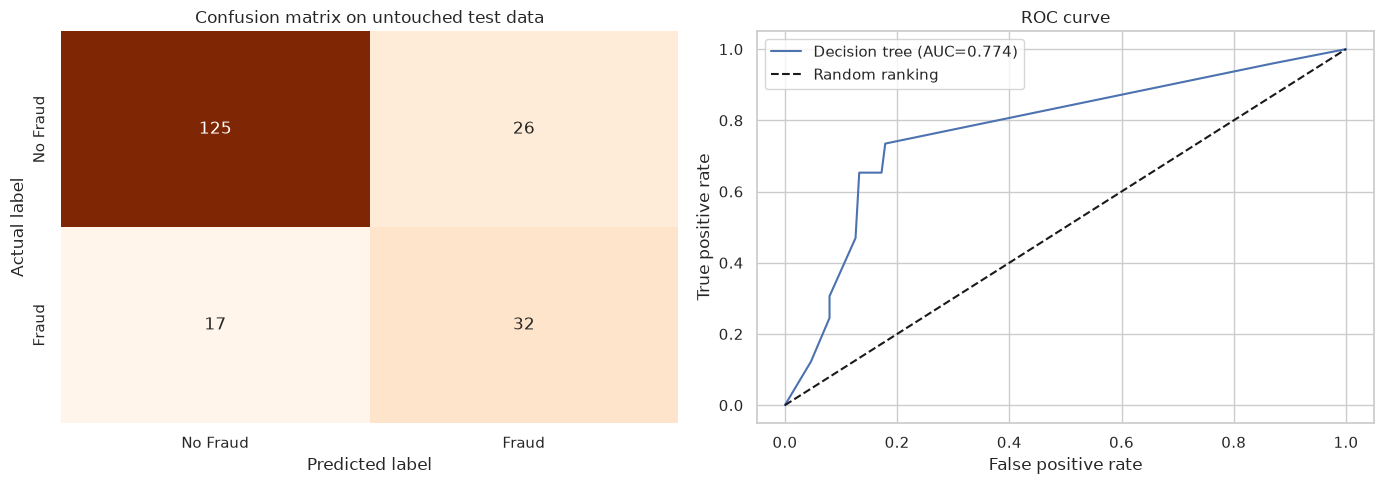

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["No Fraud", "Fraud"],
    yticklabels=["No Fraud", "Fraud"],
    ax=axes[0],
)
axes[0].set_title("Confusion matrix on untouched test data")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f"Decision tree (AUC={test_metrics['ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random ranking")
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend()
plt.tight_layout()
plt.show()
            

,importance
categorical__incident_severity_Major Damage,0.779323
numeric__auto_year,0.059219
numeric__policy_annual_premium,0.042651
categorical__insured_occupation_other-service,0.040680
numeric__vehicle_claim,0.033301
numeric__capital-loss,0.016673
numeric__incident_hour_of_the_day,0.015517
numeric__property_claim,0.012635
numeric__umbrella_limit,0.000000
numeric__capital-gains,0.000000


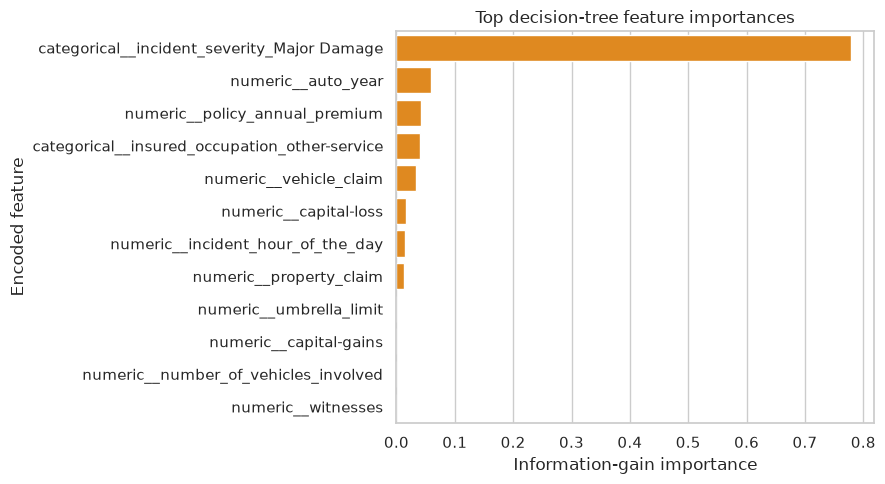

In [15]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
tree_classifier = model.named_steps["classifier"]
importance = (
    pd.Series(tree_classifier.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
    .head(12)
)
display(importance.rename("importance").to_frame())

plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index, color="darkorange")
plt.title("Top decision-tree feature importances")
plt.xlabel("Information-gain importance")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()
            

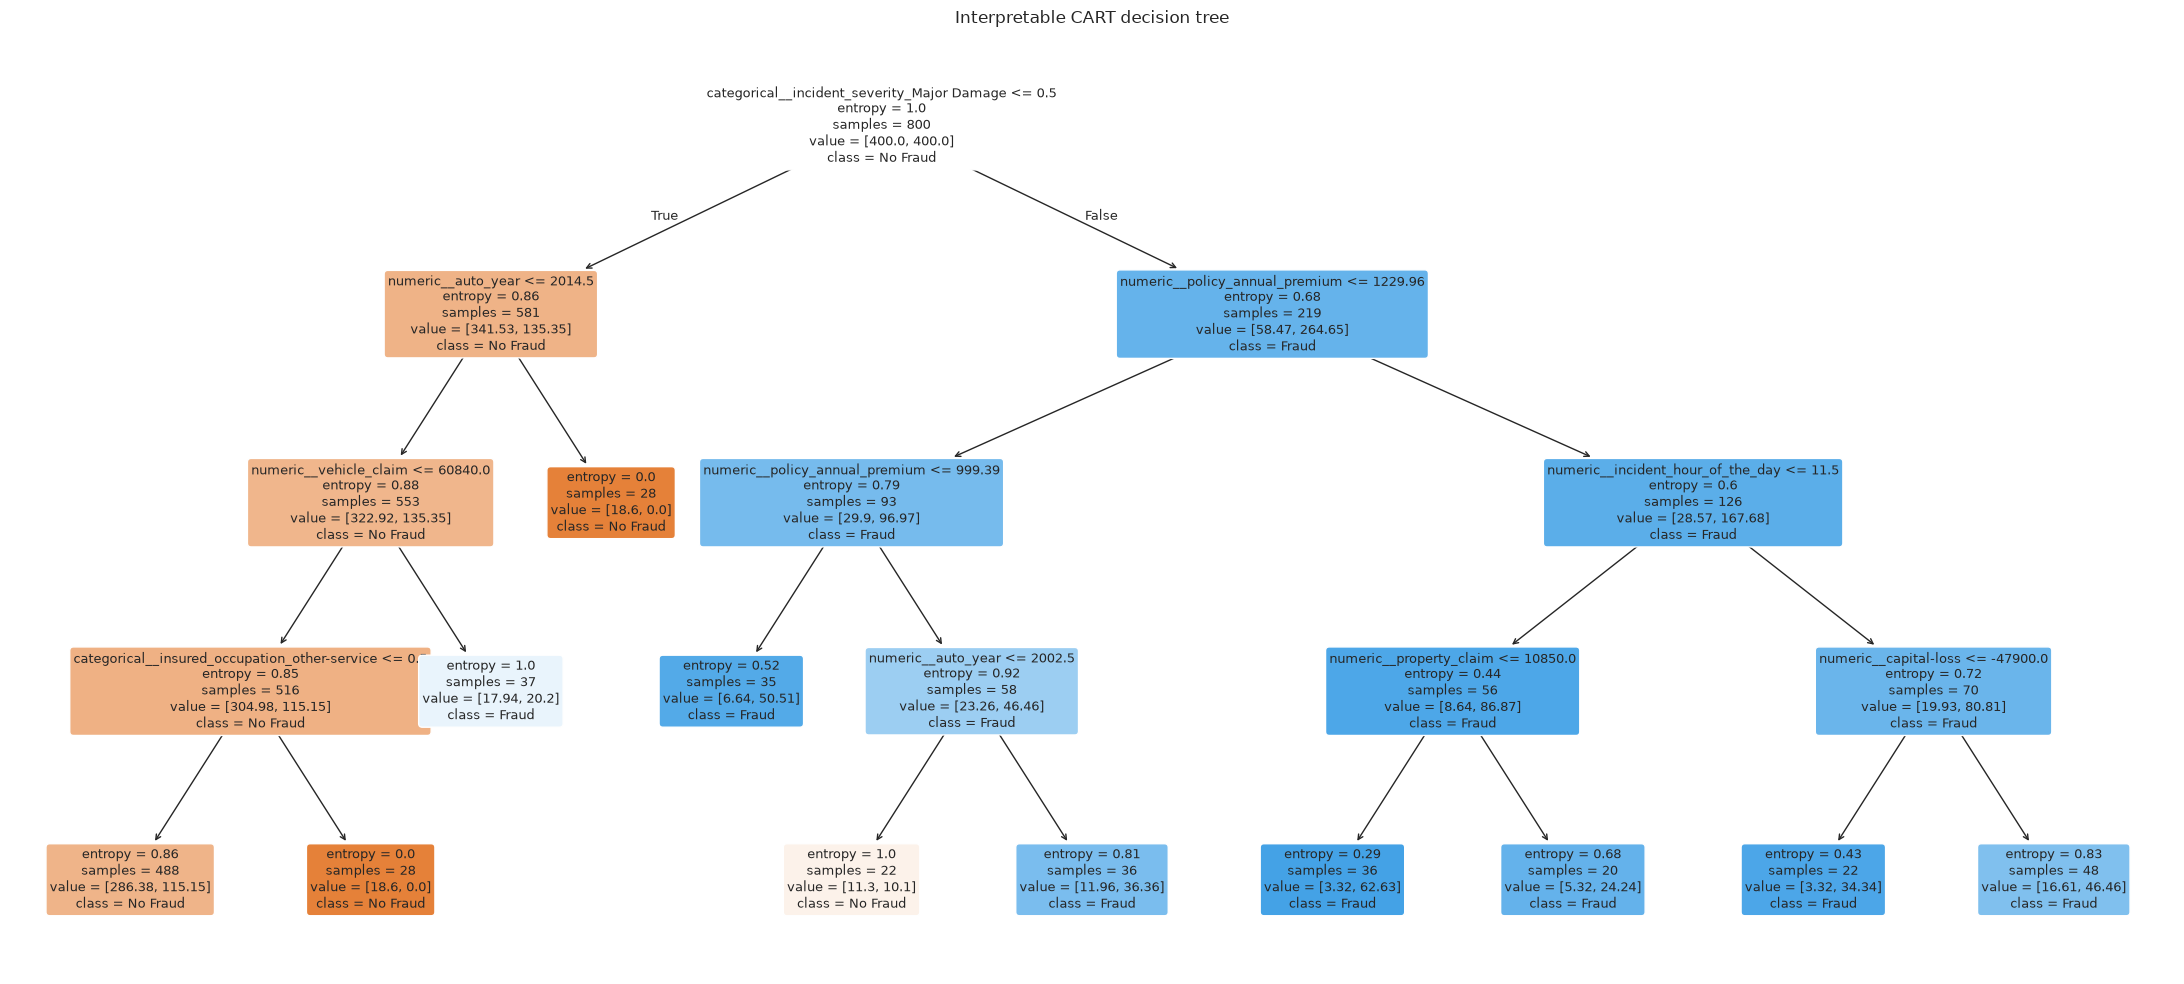

In [16]:
plt.figure(figsize=(22, 10))
plot_tree(
    tree_classifier,
    filled=True,
    feature_names=feature_names,
    class_names=["No Fraud", "Fraud"],
    rounded=True,
    precision=2,
    fontsize=9,
)
plt.title("Interpretable CART decision tree")
plt.tight_layout()
plt.show()
            

**INSIGHT - 10:** A good confusion matrix for fraud triage should be interpreted with the cost of false negatives and false positives in mind. There is no single universally best threshold.

**INSIGHT - 11:** The tree plot is intentionally shallow. If a much deeper tree produces a substantially better training score but not better validation results, that is evidence of overfitting.

## 8. Compare

Compare the five-fold validation averages with the untouched test metrics. Prefer the model only when its fraud recall, precision, F1, ROC-AUC, and specificity are considered together. For this notebook there is one deliberately constrained tree, so the main comparison is between training, cross-validation, and test behavior rather than between many unrestricted models.

**INSIGHT - 12:** Accuracy between 75% and 85% can be a reasonable educational baseline, but fraud detection should not chase a percentage target blindly. A model with high accuracy and poor fraud recall would be unsafe for investigation triage.

## 9. Summarize

The workflow loads and documents the vehicle-insurance dataset, checks class balance and missingness, removes identifiers and high-cardinality metadata, explores fraud patterns, and applies leakage-safe imputation and one-hot encoding inside a modeling pipeline. A stratified 80/20 split and stratified five-fold cross-validation preserve the rare-class proportion.

The balanced, shallow CART model is evaluated using accuracy, precision, recall/sensitivity, specificity, F1, ROC-AUC, PR-AUC, the confusion matrix, ROC curve, feature importance, and the learned tree structure.

## 10. Conclude

**Conclusion.** This decision tree is a transparent first-pass fraud-review model. The final choice should prioritize the fraud recall and precision trade-off shown in the saved outputs, while checking the validation-to-test gap for overfitting.

**Limitations.**

- The dataset is a public sample and may not represent a real insurer's claims.
- A random split does not model future time drift; a time-aware split would be stronger when dates are meaningful.
- Excluding locality, vehicle model, and raw dates simplifies the baseline but may remove useful signal.
- Class weights change the training objective but do not remove the need to choose an operational threshold.
- A prediction is a review signal, not proof of fraud; human investigation and fair-use controls remain necessary.

**Next-step direction.** Tune `max_depth`, `min_samples_leaf`, and the probability threshold using training-fold validation, then compare this tree with a leakage-safe logistic-regression or ensemble baseline.